In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('train.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [3]:
df['Age'].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

In [4]:
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])


In [5]:
df = df.drop(columns=['Cabin'])

In [6]:
print(df['Age'].isna().sum())
print(df['Embarked'].isna().sum())

0
0


In [7]:
df = pd.read_csv("train.csv")

X = df.drop(columns=["Survived"])
y = df["Survived"]

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

KeyboardInterrupt: 

In [ ]:
print("Train set size:", X_train.shape)
print("Validation set size:", X_val.shape)


Train set size: (712, 11)
Validation set size: (179, 11)


In [ ]:
features = ["Pclass", "Age", "Sex"]

X_train_selected = X_train[features]
X_val_selected = X_val[features]

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

preprocessor = ColumnTransformer([
    ("age", SimpleImputer(strategy="median"), ["Age"]),
    ("class", "passthrough", ["Pclass"]),
    ("sex", OneHotEncoder(handle_unknown="ignore"), ["Sex"])
])

model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train_selected, y_train)

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('age', ...), ('class', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [ ]:
y_pred = model.predict(X_val_selected)

accuracy = accuracy_score(y_val, y_pred)

print(f"Accuracy : {accuracy:.2%}")

Accuracy : 79.33%


In [ ]:
y_val.value_counts(normalize=True)

Survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64

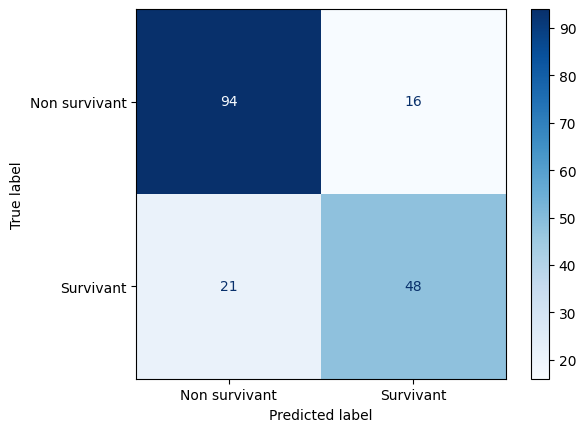

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    display_labels=["Non survivant", "Survivant"],
    cmap="Blues"
)

plt.show()

In [ ]:
y_proba = model.predict_proba(X_val_selected)[:, 1]

y_pred_20 = (y_proba >= 0.20).astype(int)

In [ ]:
from sklearn.metrics import precision_score, recall_score

print("Precision :", precision_score(y_val, y_pred_20))
print("Recall :", recall_score(y_val, y_pred_20))

Precision : 0.5686274509803921
Recall : 0.8405797101449275


In [ ]:
from sklearn.metrics import f1_score

print("F1 seuil 50 % :", f1_score(y_val, y_pred))
print("F1 seuil 20 % :", f1_score(y_val, y_pred_20))

F1 seuil 50 % : 0.7218045112781954
F1 seuil 20 % : 0.6783625730994152


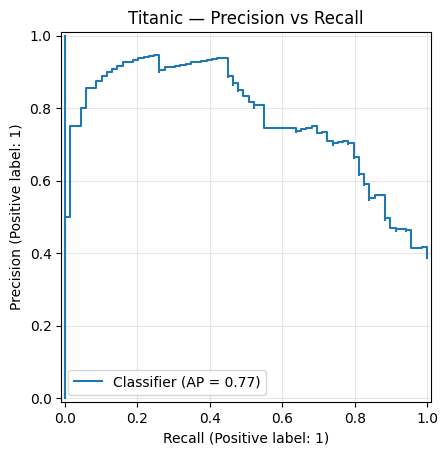

In [ ]:
from sklearn.metrics import PrecisionRecallDisplay
import matplotlib.pyplot as plt

PrecisionRecallDisplay.from_predictions(
    y_val,
    y_proba
)

plt.title("Titanic — Precision vs Recall")
plt.grid(alpha=0.3)
plt.show()


In [ ]:
features_v2 = ["Pclass", "Age", "Sex", "SibSp"]

X_train_v2 = X_train[features_v2]
X_val_v2 = X_val[features_v2]

In [ ]:
preprocessor_v2 = ColumnTransformer([
    ("age", SimpleImputer(strategy="median"), ["Age"]),
    ("numeric", "passthrough", ["Pclass", "SibSp"]),
    ("sex", OneHotEncoder(handle_unknown="ignore"), ["Sex"])
])

model_v2 = Pipeline([
    ("preprocessing", preprocessor_v2),
    ("classifier", LogisticRegression(max_iter=1000))
])

model_v2.fit(X_train_v2, y_train)

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('age', ...), ('numeric', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [ ]:
y_pred_v2 = model_v2.predict(X_val_v2)

accuracy_v2 = accuracy_score(y_val, y_pred_v2)
f1_v2 = f1_score(y_val, y_pred_v2)

print(f"Accuracy V2 : {accuracy_v2:.2%}")
print(f"F1-score V2 : {f1_v2:.4f}")

Accuracy V2 : 79.33%
F1-score V2 : 0.7176


In [ ]:
features_v3 = ["Pclass", "Age", "Sex", "Parch"]

X_train_v3 = X_train[features_v3]
X_val_v3 = X_val[features_v3]

In [ ]:
preprocessor_v3 = ColumnTransformer([
    ("age", SimpleImputer(strategy="median"), ["Age"]),
    ("numeric", "passthrough", ["Pclass", "Parch"]),
    ("sex", OneHotEncoder(handle_unknown="ignore"), ["Sex"])
])

model_v3 = Pipeline([
    ("preprocessing", preprocessor_v3),
    ("classifier", LogisticRegression(max_iter=1000))
])

model_v3.fit(X_train_v3, y_train)

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('age', ...), ('numeric', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [ ]:
y_pred_v3 = model_v3.predict(X_val_v3)

accuracy_v3 = accuracy_score(y_val, y_pred_v3)
f1_v3 = f1_score(y_val, y_pred_v3)

print(f"Accuracy V3 : {accuracy_v3:.2%}")
print(f"F1-score V3 : {f1_v3:.4f}")

Accuracy V3 : 78.21%
F1-score V3 : 0.7153


In [ ]:
features_v4 = ["Pclass", "Age", "Sex", "Fare"]

X_train_v4 = X_train[features_v4]
X_val_v4 = X_val[features_v4]

In [ ]:
preprocessor_v4 = ColumnTransformer([
    ("age", SimpleImputer(strategy="median"), ["Age"]),
    ("numeric", "passthrough", ["Pclass", "Fare"]),
    ("sex", OneHotEncoder(handle_unknown="ignore"), ["Sex"])
])

model_v4 = Pipeline([
    ("preprocessing", preprocessor_v4),
    ("classifier", LogisticRegression(max_iter=1000))
])

model_v4.fit(X_train_v4, y_train)

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('age', ...), ('numeric', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [ ]:
y_pred_v4 = model_v4.predict(X_val_v4)

accuracy_v4 = accuracy_score(y_val, y_pred_v4)
f1_v4 = f1_score(y_val, y_pred_v4)

print(f"Accuracy V4 : {accuracy_v4:.2%}")
print(f"F1-score V4 : {f1_v4:.4f}")

Accuracy V4 : 79.33%
F1-score V4 : 0.7218


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    model,
    X_train_selected,
    y_train,
    cv=cv,
    scoring="f1"
)
scores_v2 = cross_val_score(
    model_v2,
    X_train_v2,
    y_train,
    cv=cv,
    scoring="f1"
)

scores_v3 = cross_val_score(
    model_v3,
    X_train_v3,
    y_train,
    cv=cv,
    scoring="f1"
)

scores_v4 = cross_val_score(
    model_v4,
    X_train_v4,
    y_train,
    cv=cv,
    scoring="f1"
)


print("Scores :", scores)
print("F1 moyen :", scores.mean())
print("Écart-type :", scores.std())

print("Scores V2 :", scores_v2)
print("F1 moyen V2 :", scores_v2.mean())
print("Écart-type V2 :", scores_v2.std())

print("Scores V3 :", scores_v3)
print("F1 moyen V3 :", scores_v3.mean())
print("Écart-type V3 :", scores_v3.std())

print("Scores V4 :", scores_v4)
print("F1 moyen V4 :", scores_v4.mean())
print("Écart-type V4 :", scores_v4.std())


Scores : [0.73214286 0.66       0.76190476 0.71304348 0.75247525]
F1 moyen : 0.7239132689666482
Écart-type : 0.03613841329212142
Scores V2 : [0.71428571 0.68627451 0.75925926 0.69090909 0.74      ]
F1 moyen V2 : 0.7181457148515971
Écart-type V2 : 0.028072906199585426
Scores V3 : [0.71929825 0.67346939 0.72380952 0.7008547  0.75247525]
F1 moyen V3 : 0.7139814211116228
Écart-type V3 : 0.026154045686040392
Scores V4 : [0.73214286 0.66       0.76190476 0.71304348 0.74      ]
F1 moyen V4 : 0.7214182194616976
Écart-type V4 : 0.03447258189456054


In [ ]:
X_train_v5 = X_train.copy()
X_val_v5 = X_val.copy()

X_train_v5["FamilySize"] = (
    X_train_v5["SibSp"] + X_train_v5["Parch"] + 1
)

X_val_v5["FamilySize"] = (
    X_val_v5["SibSp"] + X_val_v5["Parch"] + 1
)

In [ ]:
features_v5 = ["Pclass", "Age", "Sex", "FamilySize"]

X_train_v5 = X_train_v5[features_v5]
X_val_v5 = X_val_v5[features_v5]

In [ ]:
preprocessor_v5 = ColumnTransformer([
    ("age", SimpleImputer(strategy="median"), ["Age"]),
    ("numeric", "passthrough", ["Pclass", "FamilySize"]),
    ("sex", OneHotEncoder(handle_unknown="ignore"), ["Sex"])
])

model_v5 = Pipeline([
    ("preprocessing", preprocessor_v5),
    ("classifier", LogisticRegression(max_iter=1000))
])

model_v5.fit(X_train_v5, y_train)


,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('age', ...), ('numeric', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [ ]:
scores_v5 = cross_val_score(
    model_v5,
    X_train_v5,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Scores V5 :", scores_v5)
print("F1 moyen V5 :", scores_v5.mean())
print("Écart-type V5 :", scores_v5.std())

Scores V5 : [0.71428571 0.6728972  0.75471698 0.69026549 0.74      ]
F1 moyen V5 : 0.7144330756810271
Écart-type V5 : 0.03028459677114981


In [ ]:
print("Features :", X_train_v5.columns.tolist())

print(
    "FamilySize correcte :",
    (
        X_train_v5["FamilySize"]
        == X_train["SibSp"] + X_train["Parch"] + 1
    ).all()
)

print("Préprocesseur :", model_v5.named_steps["preprocessing"])

Features : ['Pclass', 'Age', 'Sex', 'FamilySize']
FamilySize correcte : True
Préprocesseur : ColumnTransformer(transformers=[('age', SimpleImputer(strategy='median'),
                                 ['Age']),
                                ('numeric', 'passthrough',
                                 ['Pclass', 'FamilySize']),
                                ('sex', OneHotEncoder(handle_unknown='ignore'),
                                 ['Sex'])])


In [ ]:
features_v6 = ["Pclass", "Age", "Sex", "SibSp", "Parch"]

X_train_v6 = X_train[features_v6]
X_val_v6 = X_val[features_v6]

In [ ]:
preprocessor_v6 = ColumnTransformer([
    ("age", SimpleImputer(strategy="median"), ["Age"]),
    ("numeric", "passthrough", ["Pclass", "SibSp", "Parch"]),
    ("sex", OneHotEncoder(handle_unknown="ignore"), ["Sex"])
])

model_v6 = Pipeline([
    ("preprocessing", preprocessor_v6),
    ("classifier", LogisticRegression(max_iter=1000))
])

model_v6.fit(X_train_v6, y_train)


,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('age', ...), ('numeric', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [ ]:
scores_v6 = cross_val_score(
    model_v6,
    X_train_v6,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Scores V6 :", scores_v6)
print("F1 moyen V6 :", scores_v6.mean())
print("Écart-type V6 :", scores_v6.std())


Scores V6 : [0.71428571 0.6728972  0.75471698 0.67857143 0.74      ]
F1 moyen V6 : 0.7120942640501802
Écart-type V6 : 0.03243584186122116


In [ ]:
X_train_v7 = X_train.copy()
X_val_v7 = X_val.copy()

X_train_v7["IsAlone"] = (
    (X_train_v7["SibSp"] + X_train_v7["Parch"]) == 0
).astype(int)

X_val_v7["IsAlone"] = (
    (X_val_v7["SibSp"] + X_val_v7["Parch"]) == 0
).astype(int)

In [ ]:
features_v7 = ["Pclass", "Age", "Sex","IsAlone"]

X_train_v7 = X_train_v7[features_v7]
X_val_v7 = X_val_v7[features_v7]

In [ ]:
preprocessor_v7 = ColumnTransformer([
    ("age", SimpleImputer(strategy="median"), ["Age"]),
    ("numeric", "passthrough", ["Pclass", "IsAlone"]),
    ("sex", OneHotEncoder(handle_unknown="ignore"), ["Sex"])
])

model_v7 = Pipeline([
    ("preprocessing", preprocessor_v7),
    ("classifier", LogisticRegression(max_iter=1000))
])

model_v7.fit(X_train_v7, y_train)

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('age', ...), ('numeric', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [ ]:
scores_v7 = cross_val_score(
    model_v7,
    X_train_v7,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Scores V7 :", scores_v7)
print("F1 moyen V7 :", scores_v7.mean())
print("Écart-type V7 :", scores_v7.std())


Scores V7 : [0.71929825 0.67326733 0.74545455 0.70689655 0.74509804]
F1 moyen V7 : 0.7180029417482157
Écart-type V7 : 0.026885088116320812


In [ ]:

X_train_v8 = X_train.copy()
X_val_v8 = X_val.copy()

X_train_v8["FamilySize"] = (
    X_train_v8["SibSp"] + X_train_v8["Parch"] + 1
)

X_val_v8["FamilySize"] = (
    X_val_v8["SibSp"] + X_val_v8["Parch"] + 1
)


X_train_v8["IsAlone"] = (
    X_train_v8["FamilySize"] == 1
).astype(int)

X_val_v8["IsAlone"] = (
    X_val_v8["FamilySize"] == 1
).astype(int)


features_v8 = [
    "Pclass","Age","Sex","FamilySize","IsAlone","Fare"]

X_train_v8 = X_train_v8[features_v8]
X_val_v8 = X_val_v8[features_v8]


preprocessor_v8 = ColumnTransformer([
    ("impute", SimpleImputer(strategy="median"), ["Age", "Fare"]),
    ("numeric", "passthrough", ["Pclass", "FamilySize", "IsAlone"]),
    ("sex", OneHotEncoder(handle_unknown="ignore"), ["Sex"])
])


model_v8 = Pipeline([
    ("preprocessing", preprocessor_v8),
    ("classifier", LogisticRegression(max_iter=1000))
])


scores_v8 = cross_val_score(
    model_v8,
    X_train_v8,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Scores v8 :", scores_v8)
print("F1 moyen v8 :", scores_v8.mean())
print("Écart-type v8 :", scores_v8.std())



Scores v8 : [0.72727273 0.68686869 0.76470588 0.70175439 0.73786408]
F1 moyen v8 : 0.7236931520258342
Écart-type v8 : 0.02732406716368451


In [ ]:
for name, pipeline, data in [
    ("V1", model, X_train_selected),
    ("V8", model_v8, X_train_v8)
]:
    scores = cross_val_score(
        pipeline,
        data,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    print(f"{name} : {scores.mean():.4f} ± {scores.std():.4f}")

V1 : 0.7936 ± 0.0265
V8 : 0.7950 ± 0.0239


In [ ]:

train_full = pd.read_csv("train.csv")
test_kaggle = pd.read_csv("test.csv")


def create_features(data):
    data = data.copy()

    data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
    data["IsAlone"] = (data["FamilySize"] == 1).astype(int)

    return data[features_v8]

X_full = create_features(train_full)
y_full = train_full["Survived"]

X_test = create_features(test_kaggle)


model_v8.fit(X_full, y_full)


predictions = model_v8.predict(X_test)


submission = pd.DataFrame({
    "PassengerId": test_kaggle["PassengerId"],
    "Survived": predictions
})

submission.to_csv("submission_v8.csv", index=False)

print(submission.head())
print("Dimensions :", submission.shape)


   PassengerId  Survived
0          892         0
1          893         1
2          894         0
3          895         0
4          896         1
Dimensions : (418, 2)


In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

model_v8.fit(X_train_v8, y_train)

y_pred_v8 = model_v8.predict(X_val_v8)

print("Accuracy :", accuracy_score(y_val, y_pred_v8))
print("F1-score :", f1_score(y_val, y_pred_v8))
print("\nRapport de classification :\n", classification_report(y_val, y_pred_v8))
print("\nMatrice de confusion :\n", confusion_matrix(y_val, y_pred_v8))

Accuracy : 0.8100558659217877
F1-score : 0.7424242424242424

Rapport de classification :
               precision    recall  f1-score   support

           0       0.83      0.87      0.85       110
           1       0.78      0.71      0.74        69

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.80       179
weighted avg       0.81      0.81      0.81       179


Matrice de confusion :
 [[96 14]
 [20 49]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier


model_rf = Pipeline([
    ("preprocessing", preprocessor_v8),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=5,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

scores_acc_rf = cross_val_score(
    model_rf,
    X_train_v8,
    y_train,
    cv=cv,
    scoring="accuracy"
)

scores_f1_rf = cross_val_score(
    model_rf,
    X_train_v8,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Accuracy RandomForest:", scores_acc_rf)
print("Accuracy moyenne :", scores_acc_rf.mean())
print("Écart-type :", scores_acc_rf.std())
print()
print("F1 RandomForest :", scores_f1_rf)
print("F1 moyen :", scores_f1_rf.mean())




Accuracy RandomForest: [0.83916084 0.79020979 0.83802817 0.80985915 0.83098592]
Accuracy moyenne : 0.8216487737614498
Écart-type : 0.018918477941267633

F1 RandomForest : [0.78899083 0.70588235 0.75789474 0.73267327 0.76      ]
F1 moyen : 0.7490882365596174


In [ ]:
# Vérification d'un potentiel sur-apprentissage avec le RandomForestClassifier

model_rf.fit(X_train_v8, y_train)

print("Accuracy train :", model_rf.score(X_train_v8, y_train))
print("Accuracy validation :", model_rf.score(X_val_v8, y_val))

Accuracy train : 0.8455056179775281
Accuracy validation : 0.8044692737430168


In [ ]:
train_full = pd.read_csv("train.csv")
test_kaggle = pd.read_csv("test.csv")

X_full = create_features(train_full)
y_full = train_full["Survived"]
X_test = create_features(test_kaggle)

model_rf.fit(X_full, y_full)

predictions_rf = model_rf.predict(X_test)

submission_rf = pd.DataFrame({
    "PassengerId": test_kaggle["PassengerId"],
    "Survived": predictions_rf
})

submission_rf.to_csv("submission_rf.csv", index=False)

print(submission_rf.shape)
print(submission_rf.head())

(418, 2)
   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         1


In [ ]:
v8 = pd.read_csv("submission_v8.csv")
v9 = pd.read_csv("submission_rf.csv")

assert v8["PassengerId"].equals(v9["PassengerId"])

differences = v8["Survived"] != v9["Survived"]

print("Prédictions différentes :", differences.sum())
print("Prédictions identiques :", (~differences).sum())

print(pd.crosstab(
    v8["Survived"],
    v9["Survived"],
    rownames=["Logistic Regression"],
    colnames=["Random Forest"]
))

Prédictions différentes : 30
Prédictions identiques : 388
Random Forest          0    1
Logistic Regression          
0                    254   10
1                     20  134


In [ ]:
model_v8.fit(X_train_v8, y_train)
model_rf.fit(X_train_v8, y_train)

pred_v8 = model_v8.predict(X_val_v8)
pred_rf = model_rf.predict(X_val_v8)

print("Désaccords :", (pred_v8 != pred_rf).sum())

print("V8 seule correcte :", (
    (pred_v8 == y_val) & (pred_rf != y_val)
).sum())

print("RF seule correcte :", (
    (pred_rf == y_val) & (pred_v8 != y_val)
).sum())

print("Les deux incorrectes :", (
    (pred_v8 != y_val) & (pred_rf != y_val)
).sum())

Désaccords : 11
V8 seule correcte : 6
RF seule correcte : 5
Les deux incorrectes : 29


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone

params = {
    "classifier__n_estimators": [100, 200, 300, 500],
    "classifier__max_depth": [3, 4, 5, 6, 8, None],
    "classifier__min_samples_leaf": [1, 2, 3, 5, 8],
    "classifier__min_samples_split": [2, 4, 8, 12],
    "classifier__max_features": ["sqrt", "log2"]
}

search_rf = RandomizedSearchCV(
    estimator=clone(model_rf).set_params(classifier__n_jobs=1),
    param_distributions=params,
    n_iter=20,
    scoring="accuracy",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

search_rf.fit(X_train_v8, y_train)

print("Meilleurs paramètres :", search_rf.best_params_)
print("Meilleure accuracy CV :", search_rf.best_score_)
print("Accuracy train :", search_rf.best_estimator_.score(X_train_v8, y_train))

Meilleurs paramètres : {'classifier__n_estimators': 200, 'classifier__min_samples_split': 12, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'log2', 'classifier__max_depth': None}
Meilleure accuracy CV : 0.8357135821924555
Accuracy train : 0.8974719101123596


In [ ]:
best_rf = search_rf.best_estimator_

print("Accuracy train :", best_rf.score(X_train_v8, y_train))
print("Accuracy validation :", best_rf.score(X_val_v8, y_val))

y_pred_best_rf = best_rf.predict(X_val_v8)

print("F1 validation :", f1_score(y_val, y_pred_best_rf))

Accuracy train : 0.8974719101123596
Accuracy validation : 0.7821229050279329
F1 validation : 0.688


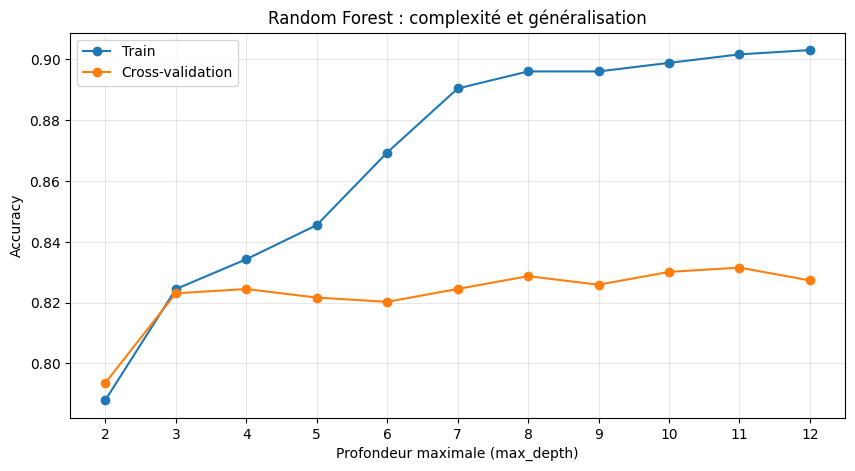

Meilleure profondeur : 11
Meilleure accuracy CV : 0.8315079286910272


In [ ]:

import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import cross_val_score

depths = range(2, 13)
train_scores = []
cv_scores = []

for depth in depths:
    model = clone(model_rf)
    model.set_params(classifier__max_depth=depth)

    scores = cross_val_score(
        model,
        X_train_v8,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    model.fit(X_train_v8, y_train)

    train_scores.append(model.score(X_train_v8, y_train))
    cv_scores.append(scores.mean())

plt.figure(figsize=(10, 5))
plt.plot(depths, train_scores, marker="o", label="Train")
plt.plot(depths, cv_scores, marker="o", label="Cross-validation")
plt.xlabel("Profondeur maximale (max_depth)")
plt.ylabel("Accuracy")
plt.title("Random Forest : complexité et généralisation")
plt.xticks(list(depths))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

best_depth = list(depths)[cv_scores.index(max(cv_scores))]

print("Meilleure profondeur :", best_depth)
print("Meilleure accuracy CV :", max(cv_scores))


In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.base import clone

cv_repeated = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=42
)

for depth in [3, 5, 8, 11]:
    candidate = clone(model_rf)
    candidate.set_params(classifier__max_depth=depth)

    scores = cross_val_score(
        candidate,
        X_train_v8,
        y_train,
        cv=cv_repeated,
        scoring="accuracy"
    )

    print(f"Depth {depth} : {scores.mean():.4f} ± {scores.std():.4f}")

Depth 3 : 0.8198 ± 0.0268
Depth 5 : 0.8207 ± 0.0216
Depth 8 : 0.8273 ± 0.0240
Depth 11 : 0.8305 ± 0.0224


IsAlone       0.001434
FamilySize    0.017142
Age           0.029757
Fare          0.039090
Pclass        0.040776
Sex           0.199230
dtype: float64


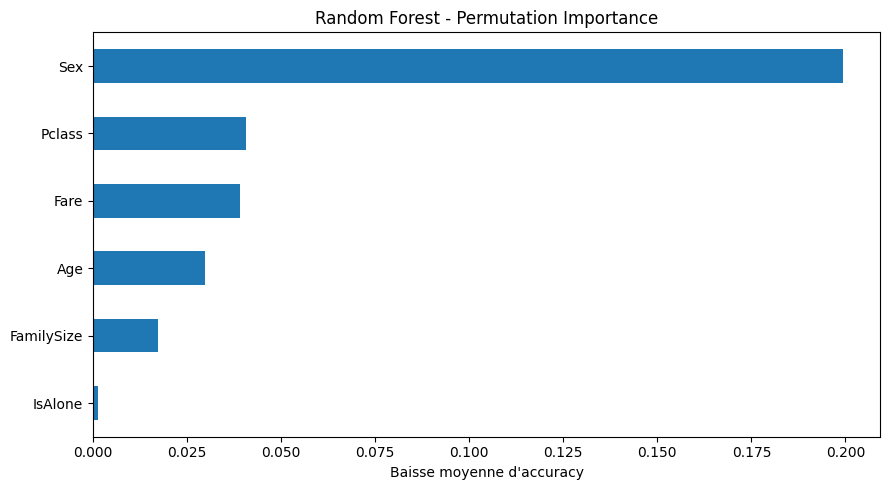

In [ ]:
from sklearn.inspection import permutation_importance

importances = []

for train_idx, val_idx in cv.split(X_train_v8, y_train):
    candidate = clone(model_rf)
    candidate.set_params(classifier__max_depth=11)

    candidate.fit(
        X_train_v8.iloc[train_idx],
        y_train.iloc[train_idx]
    )

    result = permutation_importance(
        candidate,
        X_train_v8.iloc[val_idx],
        y_train.iloc[val_idx],
        scoring="accuracy",
        n_repeats=5,
        random_state=42
    )

    importances.append(result.importances_mean)

importance_df = pd.DataFrame(
    importances,
    columns=X_train_v8.columns
)

importance_mean = importance_df.mean().sort_values()

print(importance_mean)

importance_mean.plot.barh(figsize=(9, 5))
plt.xlabel("Baisse moyenne d'accuracy")
plt.title("Random Forest - Permutation Importance")
plt.tight_layout()
plt.show()


In [ ]:
# Vérification de l'importance de la variable IsAlone avec un RandomForestClassifier

preprocessor_no_alone = ColumnTransformer([
    ("impute", SimpleImputer(strategy="median"), ["Age", "Fare"]),
    ("numeric", "passthrough", ["Pclass", "FamilySize"]),
    ("sex", OneHotEncoder(handle_unknown="ignore"), ["Sex"])
])

rf_full = clone(model_rf).set_params(classifier__max_depth=11)

rf_reduced = clone(model_rf).set_params(
    preprocessing=preprocessor_no_alone,
    classifier__max_depth=11
)

for name, candidate in [
    ("Avec IsAlone", rf_full),
    ("Sans IsAlone", rf_reduced)
]:
    scores = cross_val_score(
        candidate,
        X_train_v8,
        y_train,
        cv=cv_repeated,
        scoring="accuracy"
    )

    print(f"{name} : {scores.mean():.4f} ± {scores.std():.4f}")

Avec IsAlone : 0.8305 ± 0.0224
Sans IsAlone : 0.8305 ± 0.0231


In [ ]:
rates = df.groupby("Sex")["Survived"].mean() * 100

print(f"Femmes survivantes : {rates['female']:.2f}%")
print(f"Hommes survivants : {rates['male']:.2f}%")
print(f"Différence : {rates['female'] - rates['male']:.2f} points de pourcentage")

Femmes survivantes : 74.20%
Hommes survivants : 18.89%
Différence : 55.31 points de pourcentage


In [ ]:
analysis_df = X_train.copy()
analysis_df["Survived"] = y_train

analysis_df["Title"] = (
    analysis_df["Name"]
    .str.extract(r",\s*([^.]*)\.")[0]
    .str.strip()
)

print(
    analysis_df.groupby("Title")["Survived"]
    .agg(["count", "mean"])
    .sort_values("count", ascending=False)
    .round(3)
)

          count   mean
Title                 
Mr          412  0.153
Miss        141  0.702
Mrs         107  0.785
Master       31  0.548
Dr            6  0.500
Rev           5  0.000
Col           2  0.500
Mlle          2  1.000
Jonkheer      1  0.000
Don           1  0.000
Major         1  1.000
Lady          1  1.000
Ms            1  1.000
Sir           1  1.000


In [ ]:
# Vérification de l'importance de la variable Title avec un RandomForestClassifier

X_train_title = X_train_v8.copy()

titles = X_train["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip()

X_train_title["Title"] = titles.where(
    titles.isin(["Mr", "Mrs", "Miss", "Master"]),
    "Other"
)

preprocessor_title = ColumnTransformer([
    ("impute", SimpleImputer(strategy="median"), ["Age", "Fare"]),
    ("numeric", "passthrough", ["Pclass", "FamilySize", "IsAlone"]),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), ["Sex", "Title"])
])

model_rf_title = clone(model_rf).set_params(
    preprocessing=preprocessor_title,
    classifier__max_depth=11
)

baseline_scores = cross_val_score(
    clone(model_rf).set_params(classifier__max_depth=11),
    X_train_v8,
    y_train,
    cv=cv_repeated,
    scoring="accuracy"
)

title_scores = cross_val_score(
    model_rf_title,
    X_train_title,
    y_train,
    cv=cv_repeated,
    scoring="accuracy"
)

print(f"RF baseline : {baseline_scores.mean():.4f} ± {baseline_scores.std():.4f}")
print(f"RF + Title  : {title_scores.mean():.4f} ± {title_scores.std():.4f}")
print(f"Différence  : {title_scores.mean() - baseline_scores.mean():+.4f}")


RF baseline : 0.8305 ± 0.0224
RF + Title  : 0.8301 ± 0.0240
Différence  : -0.0005


In [ ]:
# Vérification d'un nouvel modèle RandomForestClassifier avec les mêmes features que le tutoriel Kaggle

features = ["Pclass", "Sex", "SibSp", "Parch"]

X_simple = pd.get_dummies(X_train[features])

rf_simple = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=1
)

scores = cross_val_score(
    rf_simple,
    X_simple,
    y_train,
    cv=cv_repeated,
    scoring="accuracy"
)

print(f"RF Kaggle tutorial : {scores.mean():.4f} ± {scores.std():.4f}")

RF Kaggle tutorial : 0.7931 ± 0.0243


In [ ]:
# Vérification d'un nouvel modèle RandomForestClassifier avec les mêmes features que le tutoriel Kaggle, mais avec une profondeur plus importante

X_simple = pd.get_dummies(
    X_train[["Pclass", "Sex", "SibSp", "Parch"]]
)

rf_simple_v2 = clone(model_rf.named_steps["classifier"])
rf_simple_v2.set_params(max_depth=11)

scores = cross_val_score(
    rf_simple_v2,
    X_simple,
    y_train,
    cv=cv_repeated,
    scoring="accuracy"
)

print(f"RF simple : {scores.mean():.4f} ± {scores.std():.4f}")

RF simple : 0.7940 ± 0.0309


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

model_gb = clone(model_rf).set_params(
    classifier=GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
)

scores_gb = cross_val_score(
    model_gb,
    X_train_v8,
    y_train,
    cv=cv_repeated,
    scoring="accuracy"
)

print(f"Gradient Boosting : {scores_gb.mean():.4f} ± {scores_gb.std():.4f}")

Gradient Boosting : 0.8329 ± 0.0239


In [ ]:
# Comparaison des performances entre le RandomForestClassifier et le GradientBoostingClassifier

rf_11 = clone(model_rf).set_params(classifier__max_depth=11)

scores_rf = cross_val_score(
    rf_11, X_train_v8, y_train,
    cv=cv_repeated, scoring="accuracy"
)

scores_gb = cross_val_score(
    model_gb, X_train_v8, y_train,
    cv=cv_repeated, scoring="accuracy"
)

diff = scores_gb - scores_rf

print("Gain moyen :", diff.mean())
print("GB meilleur :", (diff > 0).sum(), "/ 15")
print("RF meilleure :", (diff < 0).sum(), "/ 15")
print("Égalités :", (diff == 0).sum())

Gain moyen : 0.0023211530253783716
GB meilleur : 7 / 15
RF meilleure : 2 / 15
Égalités : 6


In [ ]:
# Installation de XGBoost , un algorithme de boosting très performant pour les problèmes de classification et de régression
from xgboost import XGBClassifier
from sklearn.model_selection import cross_validate


In [ ]:
model_xgb = clone(model_rf).set_params(
    classifier=XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    )
)

scores_xgb = cross_validate(
    model_xgb,
    X_train_v8,
    y_train,
    cv=cv_repeated,
    scoring=["accuracy", "f1"],
    n_jobs=-1
)

print(f"Accuracy XGBoost : {scores_xgb['test_accuracy'].mean():.4f} ± {scores_xgb['test_accuracy'].std():.4f}")
print(f"F1 XGBoost : {scores_xgb['test_f1'].mean():.4f} ± {scores_xgb['test_f1'].std():.4f}")

Accuracy XGBoost : nan ± nan
F1 XGBoost : nan ± nan


c:\Users\nolan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
1 fits failed out of a total of 15.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\nolan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\nolan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "c:\Users\nolan\AppData\

In [ ]:
# Comparaison des performances entre le RandomForestClassifier, le GradientBoostingClassifier et le XGBoostClassifier
# Nos 3 modèles compétifs

models = {
    "Random Forest": clone(model_rf).set_params(
        classifier__max_depth=11,
        classifier__n_jobs=1
    ),
    "Gradient Boosting": model_gb,
    "XGBoost": model_xgb
}

for name, candidate in models.items():
    scores = cross_validate(
        candidate,
        X_train_v8,
        y_train,
        cv=cv_repeated,
        scoring=["accuracy", "f1"],
        n_jobs=-1
    )

    accuracy = scores["test_accuracy"]
    f1 = scores["test_f1"]

    print(f"{name}")
    print(f"Accuracy : {accuracy.mean():.4f} ± {accuracy.std():.4f}")
    print(f"F1       : {f1.mean():.4f} ± {f1.std():.4f}\n")

Random Forest
Accuracy : 0.8305 ± 0.0224
F1       : 0.7665 ± 0.0346

Gradient Boosting
Accuracy : 0.8329 ± 0.0239
F1       : 0.7687 ± 0.0393

XGBoost
Accuracy : 0.8310 ± 0.0334
F1       : 0.7673 ± 0.0481



In [ ]:

model_gb.fit(X_train_v8, y_train)

pred_gb = model_gb.predict(X_val_v8)

print("Accuracy :", accuracy_score(y_val, pred_gb))
print("F1 :", f1_score(y_val, pred_gb))
print("Matrice de confusion :")
print(confusion_matrix(y_val, pred_gb))

Accuracy : 0.7877094972067039
F1 : 0.6885245901639344
Matrice de confusion :
[[99 11]
 [27 42]]


In [ ]:
print("Accuracy train GB :", model_gb.score(X_train_v8, y_train))
print("Accuracy CV GB : 0.8329")
print("Accuracy validation GB :", model_gb.score(X_val_v8, y_val))

Accuracy train GB : 0.9073033707865169
Accuracy CV GB : 0.8329
Accuracy validation GB : 0.7877094972067039


In [ ]:
rf_11 = clone(model_rf).set_params(
    classifier__max_depth=11
)

rf_age_missing = clone(rf_11).set_params(
    preprocessing__impute__add_indicator=True
)

for name, candidate in [
    ("RF baseline", rf_11),
    ("RF + Missing Indicator", rf_age_missing)
]:
    scores = cross_val_score(
        candidate,
        X_train_v8,
        y_train,
        cv=cv_repeated,
        scoring="accuracy"
    )

    print(f"{name} : {scores.mean():.4f} ± {scores.std():.4f}")


RF baseline : 0.8305 ± 0.0224
RF + Missing Indicator : 0.8216 ± 0.0255


In [ ]:
from sklearn.model_selection import GridSearchCV

inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

search = GridSearchCV(
    clone(model_rf),
    param_grid={"classifier__max_depth": [3, 5, 8, 11]},
    scoring="accuracy",
    cv=inner_cv,
    n_jobs=1
)

scores_nested = cross_val_score(
    search,
    X_train_v8,
    y_train,
    cv=outer_cv,
    scoring="accuracy",
    n_jobs=1
)

print("Scores externes :", scores_nested)
print(f"Accuracy nested CV : {scores_nested.mean():.4f}")
print(f"Écart-type : {scores_nested.std():.4f}")

Scores externes : [0.85314685 0.83916084 0.79577465 0.84507042 0.8028169 ]
Accuracy nested CV : 0.8272
Écart-type : 0.0233


In [ ]:
search.fit(X_train_v8, y_train)
print("Best parameters :", search.best_params_["classifier__max_depth"])
print("Best score :", search.best_score_)

Best parameters : 11
Best score : 0.8314718292380242


In [ ]:
print("Meilleure profondeur :", search.param_grid["classifier__max_depth"])
print("Meilleure accuracy CV :", search.best_score_)
print("Accuracy train :", search.best_estimator_.score(X_train_v8, y_train))

Meilleure profondeur : [3, 5, 8, 11]
Meilleure accuracy CV : 0.8314718292380242
Accuracy train : 0.901685393258427


In [ ]:
best_model = search.best_estimator_
print("Accuracy train :", best_model.score(X_train_v8, y_train))
print(best_model.get_params()["classifier__max_depth"])

Accuracy train : 0.901685393258427
11


In [ ]:
train_full = pd.read_csv("train.csv")
test_kaggle = pd.read_csv("test.csv")

X_full = create_features(train_full)
y_full = train_full["Survived"]
X_test = create_features(test_kaggle)

best_model.fit(X_full, y_full)
predictions_best = best_model.predict(X_test)

submission_rf_optimized = pd.DataFrame({
    "PassengerId": test_kaggle["PassengerId"],
    "Survived": predictions_best
})
    
print(submission_rf_optimized.shape)
print(submission_rf_optimized.head())

submission_rf_optimized.to_csv("submission_rf_optimized.csv", index=False)


(418, 2)
   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         0


In [ ]:
X_train_v10 = X_train_v8.copy()
X_val_v10 = X_val_v8.copy()



X_train_v10["FarePerPerson"] = X_train_v10["Fare"] / X_train_v10["FamilySize"]
X_val_v10["FarePerPerson"] = X_val_v10["Fare"] / X_val_v10["FamilySize"]



In [ ]:
preprocessor_v10 = ColumnTransformer([
    ("impute", SimpleImputer(strategy="median"), ["Age", "Fare","FarePerPerson"]),
    ("numeric", "passthrough", ["Pclass", "FamilySize", "IsAlone",]),
    ("sex", OneHotEncoder(handle_unknown="ignore"), ["Sex"])
])

model_rf_v10 = clone(model_rf).set_params(
    preprocessing=preprocessor_v10,
    classifier__max_depth=11
)

scores_rf_v10 = cross_val_score(
    model_rf_v10,
    X_train_v10,
    y_train,
    cv=cv_repeated,
    scoring="accuracy"
)

print("Scores :", scores_rf_v10)
print(f"Accuracy CV : {scores_rf_v10.mean():.4f}")
print(f"Écart-type : {scores_rf_v10.std():.4f}")

Scores : [0.82517483 0.8041958  0.85211268 0.82394366 0.85211268 0.81818182
 0.87412587 0.81690141 0.85211268 0.80985915 0.82517483 0.81818182
 0.88732394 0.82394366 0.82394366]
Accuracy CV : 0.8338
Écart-type : 0.0233


In [ ]:
rf_baseline = clone(model_rf).set_params(
    classifier__max_depth=11
)

scores_rf_baseline = cross_val_score(
    rf_baseline,
    X_train_v8,
    y_train,
    cv=cv_repeated,
    scoring="accuracy"
)

diff = scores_rf_v10 - scores_rf_baseline

print(f"Gain moyen : {diff.mean():+.4f}")
print(f"V10 meilleure : {(diff > 0).sum()} / 15")
print(f"Baseline meilleure : {(diff < 0).sum()} / 15")
print(f"Égalités : {(diff == 0).sum()} / 15")

Gain moyen : +0.0033
V10 meilleure : 7 / 15
Baseline meilleure : 4 / 15
Égalités : 4 / 15


In [ ]:
X_train_v11 = X_train_v10.copy()
X_train_v11["Embarked"] = X_train["Embarked"]

preprocessor_v11 = ColumnTransformer([
    ("impute", SimpleImputer(strategy="median"),
     ["Age", "Fare", "FarePerPerson"]),

    ("numeric", "passthrough",
     ["Pclass", "FamilySize", "IsAlone"]),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), ["Sex", "Embarked"])
])

model_rf_v11 = clone(model_rf_v10).set_params(
    preprocessing=preprocessor_v11
)

In [ ]:
scores_rf_v11 = cross_val_score(
    model_rf_v11,
    X_train_v11,
    y_train,
    cv=cv_repeated,
    scoring="accuracy"
)

print("Scores :", scores_rf_v11)
print(f"Accuracy CV : {scores_rf_v11.mean():.4f}")
print(f"Écart-type : {scores_rf_v11.std():.4f}")

Scores : [0.81818182 0.79020979 0.86619718 0.81690141 0.82394366 0.82517483
 0.86013986 0.82394366 0.83802817 0.80985915 0.82517483 0.81118881
 0.88028169 0.8028169  0.83098592]
Accuracy CV : 0.8282
Écart-type : 0.0235


In [ ]:
model_gb_v12 = clone(model_gb).set_params(
    preprocessing=preprocessor_v10
)

In [ ]:
scores=cross_val_score(
    model_gb_v12,
    X_train_v10,
    y_train,
    cv=cv_repeated,
    scoring="accuracy"
)


print("Scores :", scores)
print(f"Accuracy CV : {scores.mean():.4f}")
print(f"Écart-type : {scores.std():.4f}")

Scores : [0.83916084 0.79020979 0.85211268 0.81690141 0.84507042 0.81818182
 0.86713287 0.78873239 0.79577465 0.80985915 0.83916084 0.8041958
 0.87323944 0.8028169  0.82394366]
Accuracy CV : 0.8244
Écart-type : 0.0262


In [ ]:
# Notre classifieur RandomForest reste le meilleur parmi tout 12 test , on crée une fonction réutilisable pour préparer les données pour le modèle v10 

def prepare_v10_data(data):
    X = create_features(data)
    X["FarePerPerson"] = X["Fare"] / X["FamilySize"]
    return X

In [ ]:
train_full = pd.read_csv("train.csv")
test_kaggle = pd.read_csv("test.csv")

X_full = prepare_v10_data(train_full)
X_test = prepare_v10_data(test_kaggle)
y_full = train_full["Survived"]

model_final = clone(model_rf_v10)

model_final.fit(X_full, y_full)
predictions_final = model_final.predict(X_test)

submission_final = pd.DataFrame({
    "PassengerId": test_kaggle["PassengerId"],
    "Survived": predictions_final
})

submission_final.to_csv("submission_final.csv", index=False)

In [ ]:
"""
58022947  submission_final.csv         2026-11-05 12:34:42.650000  V10 - Random Forest - FarePerPerson - depth 11 - CV 83.38%        SubmissionStatus.COMPLETE  0.76076                 
58022295  submission_rf_optimized.csv  2026-11-05 12:08:58.490000  RF Optimized - GridSearchCV - depth 11 - Nested CV 82.72%         SubmissionStatus.COMPLETE  0.76555                 
58002445  submission_rf.csv            2026-11-05 00:02:24.943000  V9 - Random Forest - 300 trees - depth 5 - CV Acc 82.16%          SubmissionStatus.COMPLETE  0.77511                 
58001983  submission_v8.csv            2026-11-04 23:52:53.947000  V8 - Logistic Regression - FamilySize, IsAlone, Fare - CV 79.50%  SubmissionStatus.COMPLETE  0.77511                 """

Tous les modèles finissent plus ou moins par stagner au même niveau sur ce dataset. Je me suis donc penché sur une exploration plus fine pour voir quelles informations exploitables on pouvait en tirer.

En regardant de plus près, le jeu de test du Titanic sur Kaggle compte 418 passagers, et le leaderboard public n'en évalue que la moitié. Concrètement, cela signifie qu'un écart de précision se joue à peine à 2 ou 3 passagers près. Il faut garder ça en tête pour relativiser les scores.

Côté feature engineering, certaines variables qui semblaient secondaires au départ offrent finalement un vrai potentiel si on les croie intelligemment. Par exemple, on peut exploiter la colonne Ticket pour créer un indicateur TicketGroupSize et le comparer au FamilySize pour affiner la lecture des groupes de passagers.

On peut aussi modéliser les interactions de manière plus explicite en ajoutant une feature comme isChild, ou en croisant le sexe et la classe ce qui est particulièrement pertinent pour une régression logistique. Je ne m'attends pas à un bond miraculeux des performances, mais en étant ambitieux, viser les 80 % de précision sur le test set me semble être un bon cap et un point final pour le projet.

In [ ]:
ticket_counts = X_train["Ticket"].value_counts()

analysis_ticket = pd.DataFrame({
    "TicketGroupSize": X_train["Ticket"].map(ticket_counts),
    "Survived": y_train
})

print(
    analysis_ticket.groupby("TicketGroupSize")["Survived"]
    .agg(["count", "mean"])
    .round(3)
)

                 count   mean
TicketGroupSize              
1                  476  0.317
2                  138  0.623
3                   42  0.595
4                   24  0.250
5                   20  0.000
6                   12  0.417


In [ ]:
data = X_train.copy()
data["Survived"] = y_train

data["TicketGroupSize"] = data["Ticket"].map(data["Ticket"].value_counts())

alone = data[(data["SibSp"] == 0) & (data["Parch"] == 0)]

print(
    alone.groupby(alone["TicketGroupSize"] > 1)["Survived"]
    .agg(["count", "mean"])
)

                 count      mean
TicketGroupSize                 
False              384  0.268229
True                50  0.540000


In [ ]:
print(
    alone.groupby(
        ["Sex", alone["TicketGroupSize"] > 1]
    )["Survived"].agg(["count", "mean"]).round(3)
)

                        count   mean
Sex    TicketGroupSize              
female False               81  0.728
       True                20  1.000
male   False              303  0.145
       True                30  0.233


même en séparant les hommes et les femmes, le partage d'un billet reste associé à un meilleur taux de survie.
Mais attention : seulement 20 observations, et il reste un facteur important à contrôler : Pclass.
Il est possible que les personnes partageant leur billet soient davantage représentées en première classe.

In [ ]:
print(
    alone.groupby([
        "Sex",
        "Pclass",
        alone["TicketGroupSize"] > 1
    ])["Survived"].agg(["count", "mean"]).round(3)
)

                               count   mean
Sex    Pclass TicketGroupSize              
female 1      False               11  0.909
              True                18  1.000
       2      False               21  0.905
       3      False               49  0.612
              True                 2  1.000
male   1      False               52  0.346
              True                 9  0.222
       2      False               55  0.091
              True                 7  0.000
       3      False              196  0.107
              True                14  0.357


In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

class TicketCount(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.counts_ = X.iloc[:, 0].value_counts()
        return self

    def transform(self, X):
        return X.iloc[:, 0].map(self.counts_).fillna(1).to_frame()

In [ ]:
X_train_ticket = X_train_v10.copy()
X_train_ticket["Ticket"] = X_train["Ticket"]

preprocessor_ticket = ColumnTransformer([
    ("impute", SimpleImputer(strategy="median"),
     ["Age", "Fare", "FarePerPerson"]),
    ("numeric", "passthrough",
     ["Pclass", "FamilySize", "IsAlone"]),
    ("sex", OneHotEncoder(handle_unknown="ignore"), ["Sex"]),
    ("ticket", TicketCount(), ["Ticket"])
])

model_rf_ticket = clone(model_rf_v10).set_params(
    preprocessing=preprocessor_ticket
)

In [ ]:
scores = cross_val_score(
    model_rf_ticket,
    X_train_ticket,
    y_train,
    cv=cv_repeated,
    scoring="accuracy"
)

print("Scores :", scores)
print(f"Accuracy CV : {scores.mean():.4f}")
print(f"Écart-type : {scores.std():.4f}")

Scores : [0.83216783 0.81118881 0.85915493 0.84507042 0.84507042 0.81818182
 0.87412587 0.80985915 0.85211268 0.81690141 0.82517483 0.81818182
 0.88028169 0.82394366 0.83098592]
Accuracy CV : 0.8362
Écart-type : 0.0216


Intéressant on progresse encore un peu , et cette fois, on exploite une information qu'on ignorait totalement dans les autres modèles : les billets partagés entre passagers 

On gagne 0,24 point de pourcentage par rapport à notre meilleur modèle !


In [ ]:
train_full = pd.read_csv("train.csv")
test_kaggle = pd.read_csv("test.csv")

X_full = prepare_v10_data(train_full)
X_test = prepare_v10_data(test_kaggle)

X_full["Ticket"] = train_full["Ticket"]
X_test["Ticket"] = test_kaggle["Ticket"]

final_ticket = clone(model_rf_ticket_v2)
final_ticket.fit(X_full, train_full["Survived"])

predictions = final_ticket.predict(X_test)

submission = pd.DataFrame({
    "PassengerId": test_kaggle["PassengerId"],
    "Survived": predictions
})

submission.to_csv("submission_ticket.csv", index=False)

In [ ]:
X_train_child = X_train_v8.copy()

X_train_child["IsChild"] = (
    X_train_child["Age"] < 16
).astype(float).where(X_train_child["Age"].notna())

X_train_child["SexPclass"] = (
    X_train_child["Sex"] + "_" + X_train_child["Pclass"].astype(str)
)

In [ ]:
preprocessor_child = ColumnTransformer([
    ("impute", SimpleImputer(strategy="median"), ["Age", "Fare", "IsChild"]),
    ("numeric", "passthrough", ["Pclass", "FamilySize", "IsAlone"]),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), ["Sex", "SexPclass"])
])

model_lr_child = clone(model_v8).set_params(
    preprocessing=preprocessor_child
)

In [ ]:
scores = cross_val_score(
    model_lr_child,
    X_train_child,
    y_train,
    cv=cv_repeated,
    scoring="accuracy"
)

print("Scores :", scores)
print(f"Accuracy CV : {scores.mean():.4f}")
print(f"Écart-type : {scores.std():.4f}")

Scores : [0.8041958  0.78321678 0.8028169  0.78873239 0.75352113 0.77622378
 0.83916084 0.75352113 0.8028169  0.8028169  0.73426573 0.74125874
 0.85915493 0.8028169  0.76056338]
Accuracy CV : 0.7870
Écart-type : 0.0338


In [ ]:
# calcul de notre baseline avec le modèle v8 pour comparer les performances avec le modèle v13

scores_v8 = cross_val_score(
    model_v8,
    X_train_v8,
    y_train,
    cv=cv_repeated,
    scoring="accuracy"
)

print(f"V8 : {scores_v8.mean():.4f}")
print(f"V13 : {scores.mean():.4f}")
print(f"Différence : {scores.mean() - scores_v8.mean():+.4f}")

V8 : 0.7959
V13 : 0.7870
Différence : -0.0089
